In [189]:
import re
import os
import pandas as pd
import numpy as np
from Bio import SeqIO
from datetime import datetime
from plotnine import *
import geopandas as gpd

In [190]:
# Read in detections dataset 

all_detect_final = pd.read_csv("./metadata/detections_data/combinedNAm_detections_2021-2024.csv", sep = ',')

In [191]:
# Read in sequences dataset (HA)
ha_sequences = pd.read_csv("./metadata/sequence_metadata/NCBI-BVBRC-GIS_ha_detectionsgeodata.tsv", sep = '\t')

In [192]:
# Generate a year_month column in both

all_detect_final["year_month"] = all_detect_final["Collection Date"].str.split("-", expand = True)[0] + "_" + all_detect_final["Collection Date"].str.split("-", expand = True)[1]
ha_sequences["year_month"] = ha_sequences["year_only"].astype(str) + "_" + ha_sequences["month_only"].astype(str).str.zfill(2)

In [193]:
# Make a dictionary with counts per year month

per_yearmonth = pd.DataFrame(all_detect_final["year_month"].value_counts()).rename({"year_month":"year_month", "count":"detections"}, axis = 1)
per_yearmonth["sequences"] = ha_sequences["year_month"].value_counts()

In [194]:
# Calculate ratio of sequences to detections

per_yearmonth["ratio"] = per_yearmonth["sequences"] / per_yearmonth["detections"]

In [195]:
# Calculate the percentage of detections per year_month

total_detect = per_yearmonth["detections"].sum()
print(total_detect)
per_yearmonth["pct_detect"] = per_yearmonth["detections"] / total_detect
print(per_yearmonth["pct_detect"].sum()) # This should add up to ~1, its just a check

13335
0.9999999999999998


In [196]:
# Cacluate the smallest ratio of sequences per detections

smallest_ratio = per_yearmonth[per_yearmonth["ratio"].eq(per_yearmonth["ratio"].min())]
print(smallest_ratio)

            detections  sequences  ratio  pct_detect
year_month                                          
2024_09             30        3.0    0.1     0.00225


In [197]:
# If you only have X sequences from that year-month, and that is P percent of the total, what is the total

limiting_sequences = float(smallest_ratio["sequences"].iloc[0]) # limiting sequences is the number of sequences where there is the biggest difference between seq and detect
limiting_pct = float(smallest_ratio["pct_detect"].iloc[0]) # limiting percentage is the percent of detections where there is the biggest difference between seq and detect
avail_seq = limiting_sequences / limiting_pct
print(avail_seq)

1333.4999999999998


In [198]:
# Use the above to determine the total number of sequences you can use

per_yearmonth["seq_to_use_raw"] = per_yearmonth["pct_detect"] * avail_seq
print(per_yearmonth["seq_to_use_raw"].sum())

1333.4999999999998


In [199]:
# Round the sequence number to use to the nearest whole number

per_yearmonth["seq_to_use"] = np.floor(per_yearmonth["seq_to_use_raw"])

# If you're supposed to use 0.0 sequences (rounded), use 1
per_yearmonth.loc[per_yearmonth["seq_to_use"] == 0.0, "seq_to_use"] = 1

print(per_yearmonth["seq_to_use"].sum())

1309.0


In [200]:
print(len(per_yearmonth))
# print(per_yearmonth)

38


In [201]:
per_yearmonth_dict = per_yearmonth.to_dict(orient = "index")
print(per_yearmonth_dict)

{'2022_09': {'detections': 1250, 'sequences': 693.0, 'ratio': 0.5544, 'pct_detect': 0.09373828271466067, 'seq_to_use_raw': 124.99999999999999, 'seq_to_use': 124.0}, '2022_04': {'detections': 1105, 'sequences': 831.0, 'ratio': 0.7520361990950226, 'pct_detect': 0.08286464191976003, 'seq_to_use_raw': 110.49999999999999, 'seq_to_use': 110.0}, '2022_11': {'detections': 1098, 'sequences': 479.0, 'ratio': 0.43624772313296906, 'pct_detect': 0.08233970753655794, 'seq_to_use_raw': 109.79999999999998, 'seq_to_use': 109.0}, '2023_11': {'detections': 1029, 'sequences': 254.0, 'ratio': 0.2468415937803693, 'pct_detect': 0.07716535433070866, 'seq_to_use_raw': 102.89999999999998, 'seq_to_use': 102.0}, '2022_10': {'detections': 902, 'sequences': 343.0, 'ratio': 0.3802660753880266, 'pct_detect': 0.06764154480689914, 'seq_to_use_raw': 90.19999999999999, 'seq_to_use': 90.0}, '2022_05': {'detections': 796, 'sequences': 673.0, 'ratio': 0.8454773869346733, 'pct_detect': 0.05969253843269591, 'seq_to_use_raw': 

In [202]:
per_yearmonth = per_yearmonth.reset_index()

In [203]:
month_order = ["2021_11","2021_12", "2022_01", "2022_02", "2022_03", "2022_04", "2022_05", "2022_06",
               "2022_07", "2022_08", "2022_09", "2022_10", "2022_11", "2022_12","2023_01", "2023_02", "2023_03", "2023_04", 
               "2023_05", "2023_06", "2023_07", "2023_08", "2023_09", "2023_10", "2023_11", "2023_12", "2024_01", "2024_02", 
               "2024_03", "2024_04", "2024_05", "2024_06","2024_07", "2024_08", "2024_09", "2024_10", "2024_11", "2024_12"]

per_yearmonth["year_month"] = pd.Categorical(per_yearmonth["year_month"], categories=month_order, ordered=True)

In [204]:
per_yearmonth.head()

,year_month,detections,sequences,ratio,pct_detect,seq_to_use_raw,seq_to_use
0,2022_09,1250,693.0,0.554400,0.093738,125.0,124.0
1,2022_04,1105,831.0,0.752036,0.082865,110.5,110.0
2,2022_11,1098,479.0,0.436248,0.082340,109.8,109.0
3,2023_11,1029,254.0,0.246842,0.077165,102.9,102.0
4,2022_10,902,343.0,0.380266,0.067642,90.2,90.0


/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/layer.py:344: PlotnineWarning: position_stack : Removed 1 rows containing missing values.


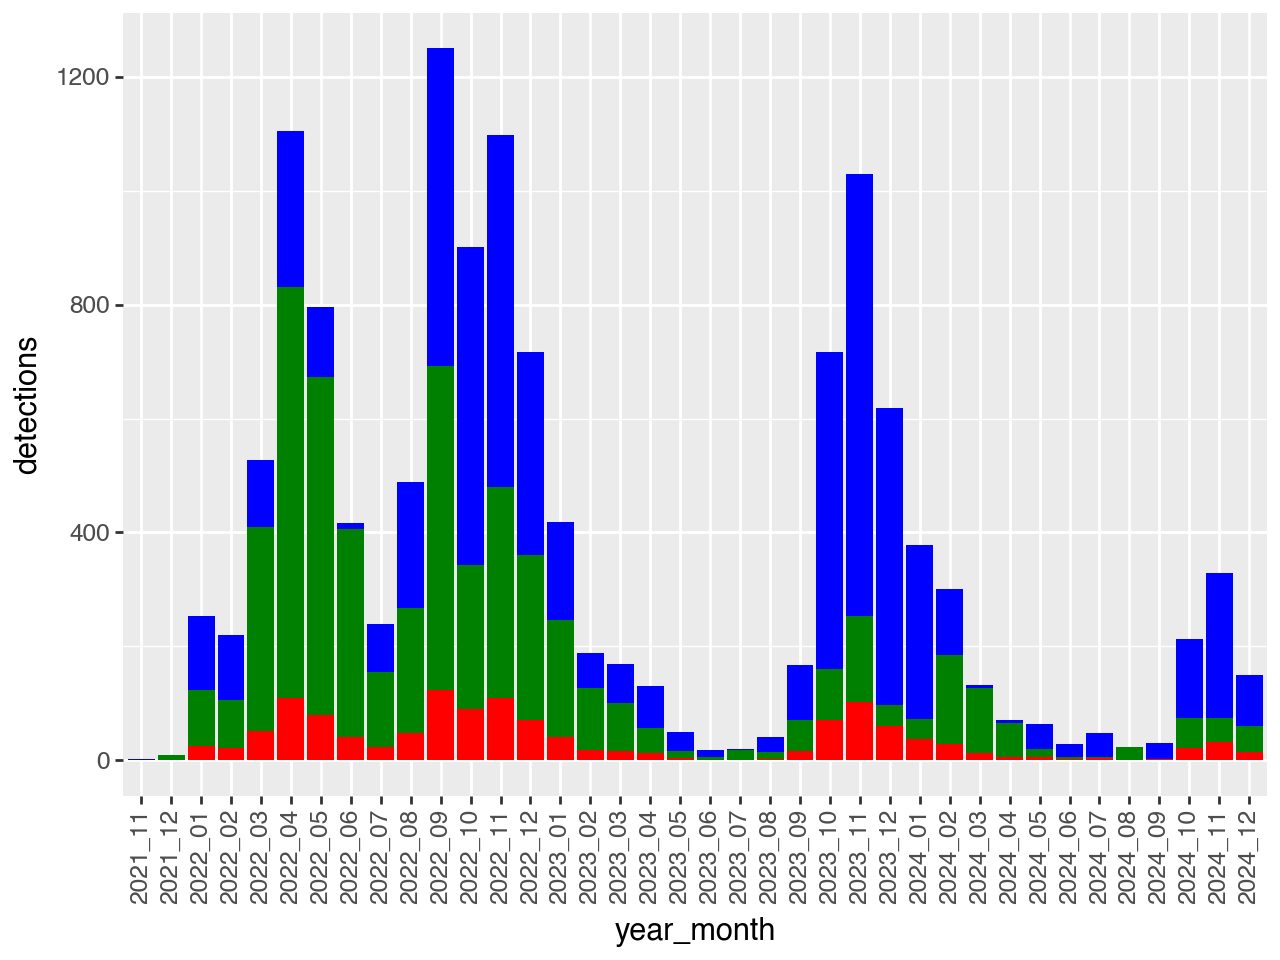

In [17]:
plot = (
    ggplot(per_yearmonth, aes(x = "year_month"))
    + geom_bar(aes(y = "detections"), stat = "identity", fill = "blue")
    + geom_bar(aes(y = "sequences"), stat = "identity", fill = "green")
    + geom_bar(aes(y = "seq_to_use"), stat = "identity", fill = "red")
    + theme(axis_text_x=element_text(rotation=90))
)

plot.show()

In [205]:
# Group detections by year_month and then count locations per year_month

year_month_location = pd.DataFrame(all_detect_final.groupby("year_month")["Location"].value_counts())

In [206]:
# What proportion of each year_month is seen in each location

year_month_location = year_month_location.reset_index() # reset index so you can use it to calculate

for idx, row in year_month_location.iterrows():
    
    time = row["year_month"]
    place = row["Location"]
    count = row["count"]

    total = per_yearmonth_dict[time]["detections"]

    year_month_location.at[idx, "percent_loc_per_yrmon"] = count / total

In [207]:
# Turn this dataframe into a dictionary with the count and percent of this location per year_month detecctions for each year_month and location

location_per_yrmon_dict = {}

for idx, row in year_month_location.iterrows():
    ym = row["year_month"]
    loc = row["Location"]
    count = row["count"]
    percent = row["percent_loc_per_yrmon"]

    if ym not in location_per_yrmon_dict:
        location_per_yrmon_dict[ym] = {}
    
    location_per_yrmon_dict[ym][loc] = {
        "count": count,
        "percent_loc_per_yrmon": percent
    }

In [208]:
# print(location_per_yrmon_dict)

In [209]:
year_month_location.head()

,year_month,Location,count,percent_loc_per_yrmon
0,2021_11,newfoundland,2,1.000000
1,2021_12,newfoundland,4,0.500000
2,2021_12,northcarolina,2,0.250000
3,2021_12,southcarolina,2,0.250000
4,2022_01,northcarolina,125,0.494071


In [210]:
seqperloc_dict = {}

for key in location_per_yrmon_dict:
    yrmon = key
    # print(key)
    
    location_dict = location_per_yrmon_dict[key]
    # print(location_dict)

    locations = list(location_dict)
    # print(locations)

    seqperloc_dict[key] = {}

    for i in locations:
        location_name = i
        pct_detect_per_loc = location_dict[i]["percent_loc_per_yrmon"]
        seq_per_yrmon = per_yearmonth_dict[yrmon]["seq_to_use"]
        seq_per_loc_raw = pct_detect_per_loc * seq_per_yrmon
        # print(i, seq_per_yrmon, seq_per_loc_raw)
       
        seqperloc_dict[key].update({location_name:{"yrmon_seq": seq_per_yrmon, "yrmon_loc_seq_raw": seq_per_loc_raw}}) # Replacing numbers with same per location

In [211]:
# print(seqperloc_dict)

In [229]:
def create_minidict(seqperloc_dict, key):
    mini_dict = {key:{}}

    yrmon = key
    for location in seqperloc_dict[key]:
        seq_per_yrmon_rounded = seqperloc_dict[key][location]['yrmon_loc_seq_rounded']
        # print(seq_per_yrmon_rounded)
        if seq_per_yrmon_rounded > 0:
            # print(location, "yes", seqperloc_dict[key][location]['yrmon_loc_seq_rounded'])
            pass
        else:
            # print(location, "no")
            mini_dict[key].update({location:seqperloc_dict[key][location]['yrmon_loc_seq_raw']})
    
    return(mini_dict)

In [230]:
mini_dict = create_minidict(seqperloc_dict, "2022_01")
print(mini_dict)

{'2022_01': {'newfoundland': 0.4940711462450593, 'virginia': 0.3952569169960474, 'florida': 0.2964426877470355, 'georgia': 0.1976284584980237, 'louisiana': 0.09881422924901186, 'maryland': 0.09881422924901186, 'princeedwardisland': 0.09881422924901186}}


In [238]:
# testy_dict[key].update({location_name:{"yrmon_seq": seq_per_yrmon, "yrmon_loc_seq": seq_per_loc_raw}}) # Replacing numbers with same per location

for key in seqperloc_dict:
    no_locations = len(seqperloc_dict[key])
    sum_seq = per_yearmonth_dict[key]["seq_to_use"]

    for location_name in seqperloc_dict[key]:
        
        seq_per_yrmon = seqperloc_dict[key][location_name]["yrmon_seq"]
        seq_per_yrmon_raw = seqperloc_dict[key][location_name]["yrmon_loc_seq_raw"]
        # print(seq_per_yrmon, seq_per_yrmon_raw)
        
        seq_per_yrmon_rounded = round(seqperloc_dict[key][location_name]["yrmon_loc_seq_raw"])
        seqperloc_dict[key][location_name]["yrmon_loc_seq_rounded"] = seq_per_yrmon_rounded

        # If there is only 1 sequences in that month
        if seq_per_yrmon == 1: 
            
            # If there is 1 sequence per month and one location
            if no_locations == 1: 
                seqperloc_dict[key][location_name]["yrmon_loc_seq_final"] = 1 # Take the sequence from that location
            
            # If there is 1 sequence per month but more locations
            elif no_locations > 1: 
                # only_loc = max(seqperloc_dict[key][location_name]["yrmon_loc_seq_raw"], key = lambda k:testy_dict[key][location_name]) # My version
                only_loc = max(seqperloc_dict[key], key=lambda loc: seqperloc_dict[key][loc]["yrmon_loc_seq_raw"]) #Chat GPT's version
                if location_name == only_loc: 
                    seqperloc_dict[key][location_name]["yrmon_loc_seq_final"] = 1 # Take the sequence from this location
                else:
                    seqperloc_dict[key][location_name]["yrmon_loc_seq_final"] = 0

            else: 
                print("something odd that I didn't expect is happening!")

        # If there is more than one sequence per month, there may be issues with multiple locations with 0 final seqs
        elif seq_per_yrmon > 1:# and no_locations > seq_per_yrmon: 
            if seq_per_yrmon_rounded > 0:
                seqperloc_dict[key][location_name]["yrmon_loc_seq_final"] = seq_per_yrmon_rounded
                #pass
            elif seq_per_yrmon_rounded == 0: # for the collection of locations where seq_per_yrmon_rounded is 0
                mini_dict = create_minidict(seqperloc_dict, key)
                # print(mini_dict)
                only_loc = max(mini_dict[key], key=lambda loc: mini_dict[key][loc])
                # print(key, only_loc)
                if location_name == only_loc: 
                    seqperloc_dict[key][location_name]["yrmon_loc_seq_final"] = 1 # Take the sequence from this location
                else:
                    seqperloc_dict[key][location_name]["yrmon_loc_seq_final"] = 0

In [239]:
print(seqperloc_dict)

{'2021_11': {'newfoundland': {'yrmon_seq': 1.0, 'yrmon_loc_seq_raw': 1.0, 'yrmon_loc_seq_rounded': 1, 'yrmon_loc_seq_final': 1}}, '2021_12': {'newfoundland': {'yrmon_seq': 1.0, 'yrmon_loc_seq_raw': 0.5, 'yrmon_loc_seq_rounded': 0, 'yrmon_loc_seq_final': 1}, 'northcarolina': {'yrmon_seq': 1.0, 'yrmon_loc_seq_raw': 0.25, 'yrmon_loc_seq_rounded': 0, 'yrmon_loc_seq_final': 0}, 'southcarolina': {'yrmon_seq': 1.0, 'yrmon_loc_seq_raw': 0.25, 'yrmon_loc_seq_rounded': 0, 'yrmon_loc_seq_final': 0}}, '2022_01': {'northcarolina': {'yrmon_seq': 25.0, 'yrmon_loc_seq_raw': 12.351778656126482, 'yrmon_loc_seq_rounded': 12, 'yrmon_loc_seq_final': 12}, 'newhampshire': {'yrmon_seq': 25.0, 'yrmon_loc_seq_raw': 4.545454545454546, 'yrmon_loc_seq_rounded': 5, 'yrmon_loc_seq_final': 5}, 'southcarolina': {'yrmon_seq': 25.0, 'yrmon_loc_seq_raw': 2.1739130434782608, 'yrmon_loc_seq_rounded': 2, 'yrmon_loc_seq_final': 2}, 'tennessee': {'yrmon_seq': 25.0, 'yrmon_loc_seq_raw': 1.8774703557312251, 'yrmon_loc_seq_round